# GAN con Google Quick Draw: Red Generadora vs. Red Discriminadora

Este proyecto entrena una **Red Generativa Adversaria (GAN)** que aprende a dibujar
bocetos de la categoría **`cat` (gato)** del conjunto de datos
[Google Quick, Draw!](https://quickdraw.withgoogle.com/data).

Una GAN tiene **dos redes neuronales** que compiten entre sí:

| Red | Qué recibe | Qué devuelve | Objetivo |
|---|---|---|---|
| **Generadora (G)** | Un vector de ruido aleatorio `z` (100 números) | Una imagen falsa de 28x28 | Engañar al discriminador |
| **Discriminadora (D)** | Una imagen de 28x28 (real o falsa) | Probabilidad de que la imagen sea **real** (0 a 1) | No dejarse engañar |

Referencias usadas:
- Curso de GAN de Google: https://developers.google.com/machine-learning/gan?hl=es-419
- GAN Lab (visualización interactiva): https://poloclub.github.io/ganlab/
- Datos Quick Draw: https://quickdraw.withgoogle.com/data

**Cómo ejecutarlo:** `python gan_quickdraw.py` (o abrir `GAN_QuickDraw.ipynb`).
Las imágenes y los valores quedan guardados en la carpeta `resultados/`.

In [1]:
# =============================================================================
# 0. LIBRERÍAS
# =============================================================================
import csv
import json
import sys
import time
import urllib.parse
import urllib.request
from collections import OrderedDict
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# ¿Se está ejecutando dentro de Jupyter? (para mostrar las gráficas en pantalla)
EN_NOTEBOOK = "ipykernel" in sys.modules

import matplotlib

if not EN_NOTEBOOK:
    matplotlib.use("Agg")  # Como script: solo guardar las imágenes en disco
import matplotlib.pyplot as plt
from PIL import Image

# Evita errores de tildes al imprimir en la consola de Windows
try:
    sys.stdout.reconfigure(encoding="utf-8")
except Exception:
    pass

## 1. Configuración e hiperparámetros

Aquí están **todos los parámetros** que se pueden cambiar. El más importante para
la entrega es `CATEGORIA`: la clase de Quick Draw que la GAN aprende a dibujar.

In [2]:
# =============================================================================
# 1. CONFIGURACIÓN E HIPERPARÁMETROS
# =============================================================================

# --- Datos ---------------------------------------------------------------
CATEGORIA = "cat"        # <<< CATEGORÍA USADA de Quick Draw (gato). Otras: "apple", "star", "fish"...
NUM_IMAGENES = 30_000    # Cuántos dibujos de la categoría se usan para entrenar
TAM_IMAGEN = 28          # Quick Draw entrega bitmaps de 28x28 píxeles en escala de grises

# --- Red Generadora (G) --------------------------------------------------
DIM_LATENTE = 100        # Tamaño del vector de ruido z que recibe el generador
LR_GENERADOR = 2e-4      # Tasa de aprendizaje (learning rate) del generador

# --- Red Discriminadora (D) ----------------------------------------------
LR_DISCRIMINADOR = 2e-4  # Tasa de aprendizaje del discriminador
PENDIENTE_LEAKY = 0.2    # Pendiente negativa de LeakyReLU (activación del discriminador)

# --- Entrenamiento -------------------------------------------------------
TAM_LOTE = 128           # Imágenes por lote (batch size)
EPOCAS = 25              # Pasadas completas por los datos
BETA1 = 0.5              # Parámetro beta1 del optimizador Adam (valor recomendado en DCGAN)
SEMILLA = 42             # Semilla para que los resultados sean reproducibles

# --- Carpetas ------------------------------------------------------------
BASE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DIR_DATOS = BASE / "datos"
DIR_RESULTADOS = BASE / "resultados"
DIR_DATOS.mkdir(exist_ok=True)
DIR_RESULTADOS.mkdir(exist_ok=True)

# Usa la GPU (CUDA) si existe; si no, la CPU
DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(SEMILLA)
np.random.seed(SEMILLA)

# Todo lo que se imprime también se guarda en resultados/reporte_valores.txt
REPORTE = []


def imprimir(texto=""):
    """Imprime en pantalla y guarda la línea para el reporte final."""
    print(texto)
    REPORTE.append(str(texto))


# Colores fijos para las gráficas: G siempre azul, D siempre naranja
COLOR_G = "#2a78d6"
COLOR_D = "#eb6834"
COLOR_TEXTO = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae",
    "axes.labelcolor": COLOR_TEXTO,
    "xtick.color": COLOR_TEXTO,
    "ytick.color": COLOR_TEXTO,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "lines.linewidth": 2,
})


def guardar_y_mostrar(fig, nombre_archivo):
    """Guarda la figura en resultados/ y la muestra si estamos en Jupyter."""
    ruta = DIR_RESULTADOS / nombre_archivo
    fig.savefig(ruta, bbox_inches="tight", facecolor="white")
    if EN_NOTEBOOK:
        plt.show()
    else:
        plt.close(fig)
    print(f"   -> imagen guardada: resultados/{nombre_archivo}")


imprimir("=" * 70)
imprimir("CONFIGURACIÓN DE LA GAN")
imprimir("=" * 70)
imprimir(f"Categoría de Quick Draw usada : '{CATEGORIA}'")
imprimir(f"Imágenes de entrenamiento     : {NUM_IMAGENES:,}")
imprimir(f"Tamaño de imagen              : {TAM_IMAGEN}x{TAM_IMAGEN} (1 canal, escala de grises)")
imprimir(f"Dimensión del ruido z         : {DIM_LATENTE}")
imprimir(f"Tamaño de lote / épocas       : {TAM_LOTE} / {EPOCAS}")
imprimir(f"Learning rate G / D           : {LR_GENERADOR} / {LR_DISCRIMINADOR}")
imprimir(f"Optimizador                   : Adam (beta1={BETA1}, beta2=0.999)")
imprimir(f"Dispositivo                   : {DISPOSITIVO}")

CONFIGURACIÓN DE LA GAN
Categoría de Quick Draw usada : 'cat'
Imágenes de entrenamiento     : 30,000
Tamaño de imagen              : 28x28 (1 canal, escala de grises)
Dimensión del ruido z         : 100
Tamaño de lote / épocas       : 128 / 25
Learning rate G / D           : 0.0002 / 0.0002
Optimizador                   : Adam (beta1=0.5, beta2=0.999)
Dispositivo                   : cpu


## 2. Datos reales: Quick Draw

Google publica cada categoría como un archivo `.npy` con todos los dibujos
convertidos a imágenes de 28x28. Cada píxel va de 0 (fondo) a 255 (trazo).

Las imágenes se escalan al rango **[-1, 1]** porque la última capa del generador
usa `Tanh`, que produce valores en ese mismo rango.


Dibujos disponibles de 'cat': 123,202  (cada uno con 784 píxeles)
Tensor de entrenamiento: (30000, 1, 28, 28)  rango [-1, 1]
Lotes por época: 234


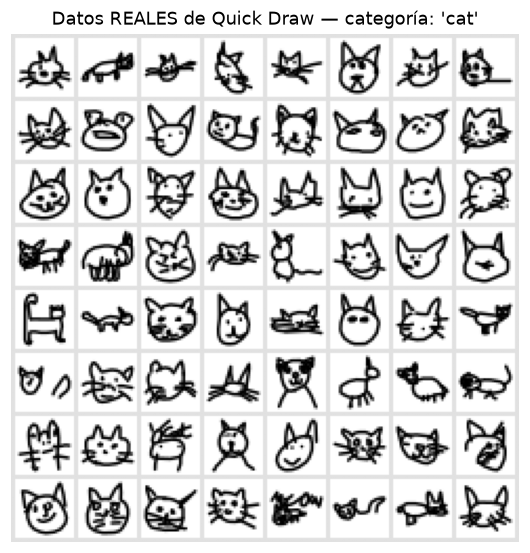

   -> imagen guardada: resultados/01_datos_reales.png


In [3]:
# =============================================================================
# 2. DESCARGA Y PREPARACIÓN DE LOS DATOS REALES (QUICK DRAW)
# =============================================================================
URL_DATOS = (
    "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/"
    f"{urllib.parse.quote(CATEGORIA)}.npy"
)
ruta_npy = DIR_DATOS / f"{CATEGORIA}.npy"

if not ruta_npy.exists():
    print(f"Descargando '{CATEGORIA}' desde Quick Draw (~100 MB)...")
    urllib.request.urlretrieve(URL_DATOS, ruta_npy)

# mmap_mode="r" lee el archivo sin cargarlo entero en memoria
todos = np.load(ruta_npy, mmap_mode="r", allow_pickle=False)  # forma: (N, 784)
imprimir()
imprimir(f"Dibujos disponibles de '{CATEGORIA}': {todos.shape[0]:,}  (cada uno con {todos.shape[1]} píxeles)")

# Se toma una muestra aleatoria de NUM_IMAGENES dibujos
generador_aleatorio = np.random.default_rng(SEMILLA)
indices = np.sort(generador_aleatorio.choice(todos.shape[0], NUM_IMAGENES, replace=False))
muestra = np.asarray(todos[indices], dtype=np.float32)

# (N, 784) -> (N, 1, 28, 28) y de [0, 255] a [-1, 1]
imagenes_reales = muestra.reshape(-1, 1, TAM_IMAGEN, TAM_IMAGEN) / 127.5 - 1.0
imprimir(f"Tensor de entrenamiento: {imagenes_reales.shape}  rango [{imagenes_reales.min():.0f}, {imagenes_reales.max():.0f}]")

cargador = DataLoader(
    TensorDataset(torch.from_numpy(imagenes_reales)),
    batch_size=TAM_LOTE,
    shuffle=True,
    drop_last=True,
)
imprimir(f"Lotes por época: {len(cargador)}")


def hacer_cuadricula(imagenes, filas, columnas, margen=2):
    """Une varias imágenes (N, 28, 28) en [-1, 1] en una sola cuadrícula."""
    imagenes = (np.asarray(imagenes).reshape(-1, TAM_IMAGEN, TAM_IMAGEN) + 1) / 2
    alto = filas * TAM_IMAGEN + (filas + 1) * margen
    ancho = columnas * TAM_IMAGEN + (columnas + 1) * margen
    lienzo = np.full((alto, ancho), 0.12)  # gris claro entre celdas
    for i in range(min(len(imagenes), filas * columnas)):
        f, c = divmod(i, columnas)
        y = margen + f * (TAM_IMAGEN + margen)
        x = margen + c * (TAM_IMAGEN + margen)
        lienzo[y:y + TAM_IMAGEN, x:x + TAM_IMAGEN] = imagenes[i]
    return lienzo


# Vista de los datos REALES (trazo negro sobre fondo blanco, como un dibujo)
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(hacer_cuadricula(imagenes_reales[:64], 8, 8), cmap="gray_r", vmin=0, vmax=1)
ax.set_title(f"Datos REALES de Quick Draw — categoría: '{CATEGORIA}'", fontsize=12)
ax.axis("off")
guardar_y_mostrar(fig, "01_datos_reales.png")

## 3. Red neuronal GENERADORA (G)

El generador **convierte ruido en un dibujo**. Recibe un vector `z` de 100 números
aleatorios (distribución normal) y lo va "agrandando" hasta formar una imagen de 28x28:

```
z (100)  ->  Linear  ->  6272 = 128 x 7 x 7  ->  ConvTranspose  ->  64 x 14 x 14  ->  ConvTranspose  ->  1 x 28 x 28
```

| Parámetro | Valor | Para qué sirve |
|---|---|---|
| Entrada | vector `z` de 100 | Fuente de aleatoriedad: cada `z` distinto da un dibujo distinto |
| Capa 1 | `Linear` 100 -> 6272 | Proyecta el ruido a un "mapa" pequeño de 128 canales de 7x7 |
| Capas 2 y 3 | `ConvTranspose2d` (kernel 4, stride 2) | Duplican el tamaño: 7 -> 14 -> 28 |
| Normalización | `BatchNorm` | Estabiliza el entrenamiento |
| Activación oculta | `ReLU` | No linealidad |
| Activación de salida | `Tanh` | Deja los píxeles en [-1, 1], igual que los datos reales |

In [4]:
# =============================================================================
# 3. RED NEURONAL GENERADORA (G)
# =============================================================================
# ╔═════════════════════════════════════════════════════════════════════════╗
# ║  AQUÍ SE DEFINE LA RED NEURONAL GENERADORA (clase Generador).           ║
# ║  Entrada: ruido z de tamaño DIM_LATENTE.  Salida: imagen 1x28x28.       ║
# ╚═════════════════════════════════════════════════════════════════════════╝
class Generador(nn.Module):
    def __init__(self, dim_latente=DIM_LATENTE):
        super().__init__()
        self.red = nn.Sequential(OrderedDict([
            # --- Capa 1: totalmente conectada (densa) -----------------------
            # Convierte el ruido z (100) en 128*7*7 = 6272 valores.
            # bias=False porque la BatchNorm siguiente ya tiene su propio sesgo.
            ("capa1_lineal", nn.Linear(dim_latente, 128 * 7 * 7, bias=False)),
            ("capa1_batchnorm", nn.BatchNorm1d(128 * 7 * 7)),
            ("capa1_relu", nn.ReLU()),
            # Reorganiza el vector de 6272 en un "mapa" de 128 canales de 7x7
            ("redimensionar", nn.Unflatten(1, (128, 7, 7))),

            # --- Capa 2: convolución transpuesta (7x7 -> 14x14) -------------
            # Reduce los canales de 128 a 64 y DUPLICA el tamaño (stride=2).
            ("capa2_deconv", nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1, bias=False)),
            ("capa2_batchnorm", nn.BatchNorm2d(64)),
            ("capa2_relu", nn.ReLU()),

            # --- Capa 3 (salida): convolución transpuesta (14x14 -> 28x28) --
            # Deja 1 solo canal (escala de grises) del tamaño final 28x28.
            ("capa3_deconv", nn.ConvTranspose2d(64, 1, kernel_size=4, stride=2, padding=1)),
            # Tanh lleva cada píxel al rango [-1, 1]
            ("salida_tanh", nn.Tanh()),
        ]))

    def forward(self, z):
        # z: (lote, 100)  ->  imagen: (lote, 1, 28, 28)
        return self.red(z)

## 4. Red neuronal DISCRIMINADORA (D)

El discriminador es un **clasificador binario**: mira una imagen y decide si es un
dibujo real de Quick Draw o una falsificación del generador. Hace el camino inverso
al generador: va **reduciendo** la imagen hasta llegar a un solo número.

```
1 x 28 x 28  ->  Conv  ->  64 x 14 x 14  ->  Conv  ->  128 x 7 x 7  ->  Linear  ->  1  ->  Sigmoid  ->  P(real)
```

| Parámetro | Valor | Para qué sirve |
|---|---|---|
| Entrada | imagen 1x28x28 | Un dibujo real o uno generado |
| Capas 1 y 2 | `Conv2d` (kernel 4, stride 2) | Extraen rasgos (trazos, orejas, bigotes) y reducen 28 -> 14 -> 7 |
| Activación oculta | `LeakyReLU(0.2)` | Deja pasar un gradiente pequeño en valores negativos (ayuda al generador a aprender) |
| Normalización | `BatchNorm` (solo en la capa 2) | Estabiliza; no se pone en la primera capa (recomendación DCGAN) |
| Capa final | `Linear` 6272 -> 1 | Un único puntaje |
| Activación de salida | `Sigmoid` | Convierte el puntaje en probabilidad: 1 = "real", 0 = "falsa" |

In [5]:
# =============================================================================
# 4. RED NEURONAL DISCRIMINADORA (D)
# =============================================================================
# ╔═════════════════════════════════════════════════════════════════════════╗
# ║  AQUÍ SE DEFINE LA RED NEURONAL DISCRIMINADORA (clase Discriminador).   ║
# ║  Entrada: imagen 1x28x28.  Salida: probabilidad de que sea REAL.        ║
# ╚═════════════════════════════════════════════════════════════════════════╝
class Discriminador(nn.Module):
    def __init__(self, pendiente=PENDIENTE_LEAKY):
        super().__init__()
        self.red = nn.Sequential(OrderedDict([
            # --- Capa 1: convolución (28x28 -> 14x14) -----------------------
            # 1 canal de entrada -> 64 filtros. Sin BatchNorm en la primera capa.
            ("capa1_conv", nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1)),
            ("capa1_leakyrelu", nn.LeakyReLU(pendiente)),

            # --- Capa 2: convolución (14x14 -> 7x7) -------------------------
            ("capa2_conv", nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False)),
            ("capa2_batchnorm", nn.BatchNorm2d(128)),
            ("capa2_leakyrelu", nn.LeakyReLU(pendiente)),

            # --- Capa 3 (salida): clasificador ------------------------------
            # Aplana 128x7x7 = 6272 valores y los resume en un solo número.
            ("aplanar", nn.Flatten()),
            ("capa3_lineal", nn.Linear(128 * 7 * 7, 1)),
            # Sigmoid: probabilidad entre 0 (falsa) y 1 (real)
            ("salida_sigmoid", nn.Sigmoid()),
        ]))

    def forward(self, imagen):
        # imagen: (lote, 1, 28, 28)  ->  probabilidad: (lote, 1)
        return self.red(imagen)

## 5. Creación de las dos redes y sus valores (parámetros)

Aquí se **crean (instancian)** las redes. Los pesos se inicializan con una
distribución normal de media 0 y desviación 0.02, como en el artículo DCGAN.
Luego se imprime cada capa con la forma de su salida y su número de parámetros
(pesos + sesgos que la red aprende).


RED GENERADORA (G): ruido z -> imagen falsa
Capa              Tipo              Forma de salida           Parámetros
------------------------------------------------------------------------------
(entrada)                           [100]                               
capa1_lineal      Linear            [6272]                       627,200
capa1_batchnorm   BatchNorm1d       [6272]                        12,544
capa1_relu        ReLU              [6272]                             0
redimensionar     Unflatten         [128, 7, 7]                        0
capa2_deconv      ConvTranspose2d   [64, 14, 14]                 131,072
capa2_batchnorm   BatchNorm2d       [64, 14, 14]                     128
capa2_relu        ReLU              [64, 14, 14]                       0
capa3_deconv      ConvTranspose2d   [1, 28, 28]                    1,025
salida_tanh       Tanh              [1, 28, 28]                        0
-------------------------------------------------------------------------

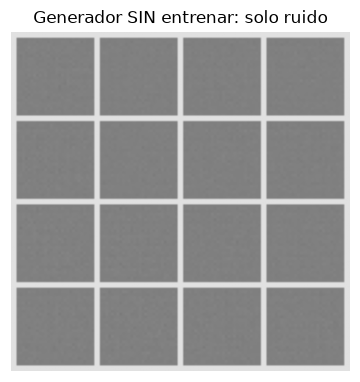

   -> imagen guardada: resultados/02_generador_sin_entrenar.png


In [6]:
# =============================================================================
# 5. CREACIÓN DE LAS REDES + VALORES DEL GENERADOR Y DEL DISCRIMINADOR
# =============================================================================
def inicializar_pesos(capa):
    """Pesos iniciales recomendados por DCGAN: Normal(0, 0.02)."""
    if isinstance(capa, (nn.Conv2d, nn.ConvTranspose2d, nn.Linear)):
        nn.init.normal_(capa.weight, 0.0, 0.02)
        if capa.bias is not None:
            nn.init.zeros_(capa.bias)
    elif isinstance(capa, (nn.BatchNorm1d, nn.BatchNorm2d)):
        nn.init.normal_(capa.weight, 1.0, 0.02)
        nn.init.zeros_(capa.bias)


# ┌─────────────────────────────────────────────────────────────────────────┐
# │  >>> AQUÍ SE CREA LA RED GENERADORA (instancia G) <<<                   │
# └─────────────────────────────────────────────────────────────────────────┘
G = Generador(DIM_LATENTE).to(DISPOSITIVO)
G.apply(inicializar_pesos)

# ┌─────────────────────────────────────────────────────────────────────────┐
# │  >>> AQUÍ SE CREA LA RED DISCRIMINADORA (instancia D) <<<               │
# └─────────────────────────────────────────────────────────────────────────┘
D = Discriminador(PENDIENTE_LEAKY).to(DISPOSITIVO)
D.apply(inicializar_pesos)


def resumen_red(modelo, entrada, titulo):
    """Imprime cada capa: nombre, tipo, forma de salida y número de parámetros."""
    filas, ganchos = [], []
    for nombre, capa in modelo.named_modules():
        if len(list(capa.children())) == 0:  # solo capas "hoja"
            def gancho(m, _entrada, salida, nombre=nombre):
                n = sum(p.numel() for p in m.parameters(recurse=False))
                filas.append((nombre.replace("red.", ""), m.__class__.__name__, list(salida.shape[1:]), n))
            ganchos.append(capa.register_forward_hook(gancho))
    modelo.eval()
    with torch.no_grad():
        modelo(entrada)
    modelo.train()
    for g in ganchos:
        g.remove()

    total = sum(p.numel() for p in modelo.parameters())
    imprimir()
    imprimir("=" * 78)
    imprimir(titulo)
    imprimir("=" * 78)
    imprimir(f"{'Capa':<18}{'Tipo':<18}{'Forma de salida':<22}{'Parámetros':>14}")
    imprimir("-" * 78)
    imprimir(f"{'(entrada)':<18}{'':<18}{str(list(entrada.shape[1:])):<22}{'':>14}")
    for nombre, tipo, forma, n in filas:
        imprimir(f"{nombre:<18}{tipo:<18}{str(forma):<22}{n:>14,}")
    imprimir("-" * 78)
    imprimir(f"{'TOTAL de parámetros entrenables:':<58}{total:>20,}")
    return total


z_prueba = torch.randn(2, DIM_LATENTE, device=DISPOSITIVO)
img_prueba = torch.randn(2, 1, TAM_IMAGEN, TAM_IMAGEN, device=DISPOSITIVO)
params_G = resumen_red(G, z_prueba, "RED GENERADORA (G): ruido z -> imagen falsa")
params_D = resumen_red(D, img_prueba, "RED DISCRIMINADORA (D): imagen -> probabilidad de ser real")


def valores_pesos(modelo, titulo):
    """Muestra los VALORES de los pesos de cada capa: media, desviación, mínimo y máximo."""
    imprimir()
    imprimir(f"--- {titulo} ---")
    imprimir(f"{'Parámetro':<28}{'Forma':<20}{'Media':>9}{'Desv.':>9}{'Mín':>9}{'Máx':>9}")
    for nombre, p in modelo.named_parameters():
        v = p.detach().float().cpu()
        imprimir(
            f"{nombre.replace('red.', ''):<28}{str(list(v.shape)):<20}"
            f"{v.mean().item():>9.4f}{v.std().item() if v.numel() > 1 else 0:>9.4f}"
            f"{v.min().item():>9.4f}{v.max().item():>9.4f}"
        )


valores_pesos(G, "Valores INICIALES de los pesos del GENERADOR (antes de entrenar)")
valores_pesos(D, "Valores INICIALES de los pesos del DISCRIMINADOR (antes de entrenar)")

# Ejemplo: los primeros 5 pesos reales de la primera capa de cada red
imprimir()
imprimir(f"Primeros 5 pesos de G.capa1_lineal : {G.red.capa1_lineal.weight.flatten()[:5].tolist()}")
imprimir(f"Primeros 5 pesos de D.capa1_conv   : {D.red.capa1_conv.weight.flatten()[:5].tolist()}")

# Lo que produce el generador SIN entrenar: solo ruido
G.eval()
with torch.no_grad():
    sin_entrenar = G(torch.randn(16, DIM_LATENTE, device=DISPOSITIVO)).cpu().numpy()
    prob_sin_entrenar = D(torch.from_numpy(sin_entrenar).to(DISPOSITIVO)).mean().item()
G.train()
imprimir(f"D(G(z)) con las redes sin entrenar: {prob_sin_entrenar:.3f}  (D aún no sabe distinguir: ~0.5)")

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(hacer_cuadricula(sin_entrenar, 4, 4), cmap="gray_r", vmin=0, vmax=1)
ax.set_title("Generador SIN entrenar: solo ruido", fontsize=11)
ax.axis("off")
guardar_y_mostrar(fig, "02_generador_sin_entrenar.png")

## 6. Funciones de pérdida

La GAN se basa en un juego **minimax** entre las dos redes
(fórmula del curso de Google y del artículo original de Goodfellow, 2014):

$$\min_G \max_D \; \mathbb{E}_x[\log D(x)] + \mathbb{E}_z[\log(1 - D(G(z)))]$$

- `D(x)`: probabilidad que D da a un dibujo **real**. D quiere que sea **1**.
- `D(G(z))`: probabilidad que D da a un dibujo **falso**. D quiere que sea **0**; G quiere que sea **1**.

En la práctica cada red tiene su propia pérdida, calculada con **entropía cruzada binaria (BCE)**:

| Red | Pérdida | Con BCE | Se minimiza cuando... |
|---|---|---|---|
| Discriminador | $L_D = -[\log D(x) + \log(1 - D(G(z)))]$ | `BCE(D(x), 1) + BCE(D(G(z)), 0)` | acierta en reales y en falsas |
| Generador | $L_G = -\log D(G(z))$ | `BCE(D(G(z)), 1)` | D cree que sus dibujos son reales |

La pérdida del generador usa la versión **"minimax modificada" (no saturante)** que
recomienda Google: en lugar de minimizar $\log(1 - D(G(z)))$ se minimiza $-\log D(G(z))$.
Así, al inicio (cuando D rechaza todo con facilidad) el generador sigue recibiendo
gradientes grandes y no se "estanca". La primera gráfica de abajo lo muestra.

*(El curso de Google también describe la **pérdida de Wasserstein**, usada en WGAN; aquí
se usa la pérdida minimax, que es la estándar.)*

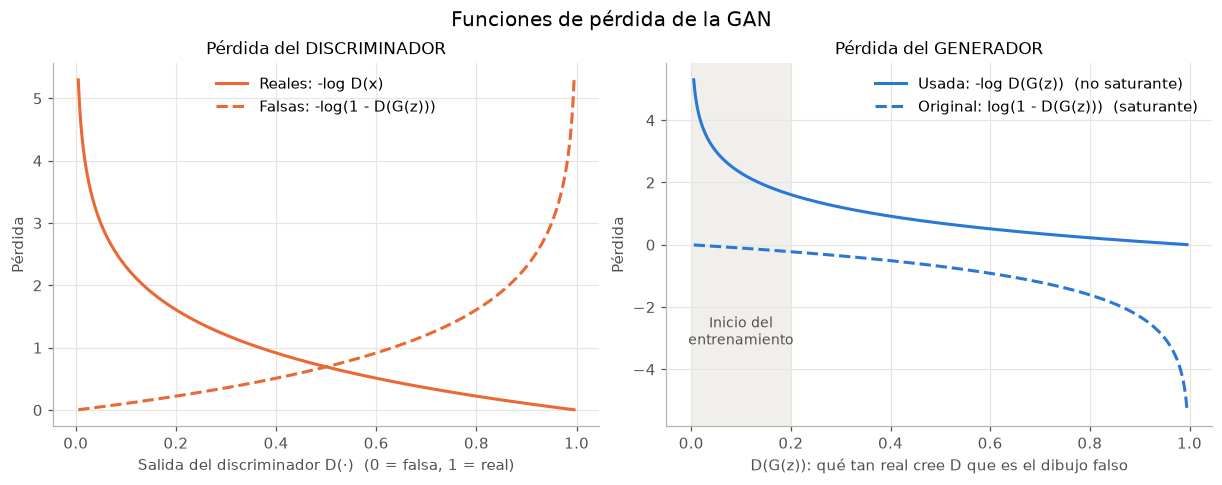

   -> imagen guardada: resultados/03_funciones_de_perdida.png


In [7]:
# =============================================================================
# 6. FUNCIONES DE PÉRDIDA
# =============================================================================
# Entropía cruzada binaria: BCE(p, y) = -[ y*log(p) + (1-y)*log(1-p) ]
#   - Con etiqueta y=1 (real) queda   -log(p)
#   - Con etiqueta y=0 (falsa) queda  -log(1-p)
bce = nn.BCELoss()


# ╔═════════════════════════════════════════════════════════════════════════╗
# ║  FUNCIÓN DE PÉRDIDA DEL DISCRIMINADOR                                   ║
# ║  L_D = -[ log D(x) + log(1 - D(G(z))) ]                                 ║
# ╚═════════════════════════════════════════════════════════════════════════╝
def perdida_discriminador(d_real, d_falso):
    # Parte 1: los dibujos REALES deben recibir etiqueta 1  ->  -log D(x)
    perdida_reales = bce(d_real, torch.ones_like(d_real))
    # Parte 2: los dibujos FALSOS deben recibir etiqueta 0  ->  -log(1 - D(G(z)))
    perdida_falsos = bce(d_falso, torch.zeros_like(d_falso))
    return perdida_reales + perdida_falsos


# ╔═════════════════════════════════════════════════════════════════════════╗
# ║  FUNCIÓN DE PÉRDIDA DEL GENERADOR (minimax modificada / no saturante)   ║
# ║  L_G = -log D(G(z))                                                     ║
# ╚═════════════════════════════════════════════════════════════════════════╝
def perdida_generador(d_falso):
    # El generador "quiere" que D marque sus dibujos falsos como REALES (etiqueta 1)
    return bce(d_falso, torch.ones_like(d_falso))


# Gráfica de las funciones de pérdida según la salida del discriminador
p = np.linspace(0.005, 0.995, 400)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.3), layout="constrained")

ax1.plot(p, -np.log(p), color=COLOR_D, label="Reales: -log D(x)")
ax1.plot(p, -np.log(1 - p), color=COLOR_D, linestyle="--", label="Falsas: -log(1 - D(G(z)))")
ax1.set_title("Pérdida del DISCRIMINADOR", fontsize=11)
ax1.set_xlabel("Salida del discriminador D(·)  (0 = falsa, 1 = real)")
ax1.set_ylabel("Pérdida")
ax1.legend(frameon=False)

ax2.plot(p, -np.log(p), color=COLOR_G, label="Usada: -log D(G(z))  (no saturante)")
ax2.plot(p, np.log(1 - p), color=COLOR_G, linestyle="--", label="Original: log(1 - D(G(z)))  (saturante)")
ax2.axvspan(0, 0.2, color="#e6e5e0", alpha=0.6, linewidth=0)
ax2.text(0.1, -3.2, "Inicio del\nentrenamiento", ha="center", fontsize=9, color=COLOR_TEXTO)
ax2.set_title("Pérdida del GENERADOR", fontsize=11)
ax2.set_xlabel("D(G(z)): qué tan real cree D que es el dibujo falso")
ax2.set_ylabel("Pérdida")
ax2.legend(frameon=False, loc="upper right")
fig.suptitle("Funciones de pérdida de la GAN", fontsize=13)
guardar_y_mostrar(fig, "03_funciones_de_perdida.png")

## 7. Optimizadores

Cada red tiene **su propio optimizador**: cuando se entrena una, la otra no cambia.
Se usa Adam con `lr = 0.0002` y `beta1 = 0.5` (valores del artículo DCGAN).

In [8]:
# =============================================================================
# 7. OPTIMIZADORES (uno para cada red)
# =============================================================================
optimizador_G = torch.optim.Adam(G.parameters(), lr=LR_GENERADOR, betas=(BETA1, 0.999))
optimizador_D = torch.optim.Adam(D.parameters(), lr=LR_DISCRIMINADOR, betas=(BETA1, 0.999))

## 8. Entrenamiento adversario

En cada lote se hacen **dos pasos alternados** (igual que en GAN Lab):

1. **Entrenar D** con un lote de dibujos reales (etiqueta 1) y uno de falsos (etiqueta 0).
2. **Entrenar G**: genera dibujos, se los muestra a D y actualiza G para que D los marque como reales.

Valores que se imprimen en cada época:

| Valor | Significado | Valor ideal al final |
|---|---|---|
| Pérdida D | Qué tan mal clasifica el discriminador | ~1.39 (= 2·ln 2) si hay equilibrio |
| Pérdida G | Qué tan mal engaña el generador | ~0.69 (= ln 2) si hay equilibrio |
| D(x) | Probabilidad promedio que D da a los dibujos **reales** | se acerca a 0.5 |
| D(G(z)) | Probabilidad promedio que D da a los dibujos **falsos** | se acerca a 0.5 |

Si D(x) y D(G(z)) se acercan a 0.5, el discriminador ya no distingue bien: el
generador está produciendo dibujos convincentes.

In [9]:
# =============================================================================
# 8. ENTRENAMIENTO ADVERSARIO
# =============================================================================
# Ruido FIJO: siempre las mismas 64 "semillas", para ver cómo mejora el mismo dibujo
ruido_fijo = torch.randn(64, DIM_LATENTE, device=DISPOSITIVO)

historial_lotes = {"perdida_D": [], "perdida_G": []}
historial_epocas = []        # una fila por época con los promedios
evolucion = {}               # imágenes generadas con ruido_fijo al final de cada época

imprimir()
imprimir("=" * 78)
imprimir(f"ENTRENAMIENTO  |  categoría '{CATEGORIA}'  |  {EPOCAS} épocas x {len(cargador)} lotes")
imprimir("=" * 78)
imprimir(f"{'Época':>7}{'Pérdida D':>12}{'Pérdida G':>12}{'D(x)':>9}{'D(G(z))':>10}{'Tiempo':>9}")
inicio_total = time.time()

for epoca in range(1, EPOCAS + 1):
    inicio = time.time()
    suma = {"perdida_D": 0.0, "perdida_G": 0.0, "D_x": 0.0, "D_G_z": 0.0}

    for (reales,) in cargador:
        reales = reales.to(DISPOSITIVO)
        lote = reales.size(0)

        # -------------------------------------------------------------------
        # PASO 1: ENTRENAR EL DISCRIMINADOR  (maximizar log D(x) + log(1 - D(G(z))))
        # -------------------------------------------------------------------
        optimizador_D.zero_grad()
        z = torch.randn(lote, DIM_LATENTE, device=DISPOSITIVO)   # ruido aleatorio
        falsas = G(z)                                            # G crea dibujos falsos

        d_real = D(reales).view(-1)             # D evalúa los reales
        d_falso = D(falsas.detach()).view(-1)   # .detach(): en este paso NO se modifica G
        perdida_D = perdida_discriminador(d_real, d_falso)
        perdida_D.backward()                    # gradientes solo para D
        optimizador_D.step()                    # actualiza los pesos de D

        # -------------------------------------------------------------------
        # PASO 2: ENTRENAR EL GENERADOR  (minimizar -log D(G(z)))
        # -------------------------------------------------------------------
        optimizador_G.zero_grad()
        d_falso_para_G = D(falsas).view(-1)     # D (ya actualizado) evalúa los falsos
        perdida_G = perdida_generador(d_falso_para_G)
        perdida_G.backward()                    # el gradiente viaja a través de D hasta G
        optimizador_G.step()                    # actualiza SOLO los pesos de G

        # Guardar valores para las gráficas
        historial_lotes["perdida_D"].append(perdida_D.item())
        historial_lotes["perdida_G"].append(perdida_G.item())
        suma["perdida_D"] += perdida_D.item()
        suma["perdida_G"] += perdida_G.item()
        suma["D_x"] += d_real.mean().item()
        suma["D_G_z"] += d_falso.mean().item()

    # Promedios de la época
    n = len(cargador)
    fila = {"epoca": epoca, **{k: v / n for k, v in suma.items()}, "segundos": time.time() - inicio}
    historial_epocas.append(fila)
    imprimir(
        f"{epoca:>4}/{EPOCAS:<2}{fila['perdida_D']:>12.4f}{fila['perdida_G']:>12.4f}"
        f"{fila['D_x']:>9.3f}{fila['D_G_z']:>10.3f}{fila['segundos']:>8.1f}s"
    )

    # Foto del progreso del generador con el ruido fijo
    G.eval()
    with torch.no_grad():
        evolucion[epoca] = G(ruido_fijo).cpu().numpy()
    G.train()

imprimir(f"Tiempo total de entrenamiento: {(time.time() - inicio_total) / 60:.1f} minutos")

# Guardar el historial de valores y los modelos entrenados
with open(DIR_RESULTADOS / "historial_entrenamiento.csv", "w", newline="", encoding="utf-8") as f:
    escritor = csv.DictWriter(f, fieldnames=list(historial_epocas[0].keys()))
    escritor.writeheader()
    escritor.writerows(historial_epocas)
torch.save(G.state_dict(), DIR_RESULTADOS / "generador.pth")
torch.save(D.state_dict(), DIR_RESULTADOS / "discriminador.pth")
print("   -> historial y modelos guardados en resultados/")


ENTRENAMIENTO  |  categoría 'cat'  |  25 épocas x 234 lotes
  Época   Pérdida D   Pérdida G     D(x)   D(G(z))   Tiempo


   1/25      0.3411      3.0528    0.884     0.128    34.2s


   2/25      0.4340      2.4252    0.837     0.160    40.2s


   3/25      0.4428      2.1861    0.826     0.176    44.2s


   4/25      0.2764      2.5135    0.880     0.119    36.1s


   5/25      0.2436      2.8450    0.906     0.095    42.4s


... (16 outputs left out)

  22/25      0.0674      4.2255    0.969     0.032    26.1s


  23/25      0.4745      3.5909    0.891     0.107    27.2s


  24/25      0.1223      3.6125    0.947     0.055    26.4s


  25/25      0.0640      4.2450    0.970     0.030    26.1s
Tiempo total de entrenamiento: 12.6 minutos
   -> historial y modelos guardados en resultados/


## 9. Valores del generador y del discriminador durante el entrenamiento

- **Pérdidas:** al inicio suelen moverse mucho; después oscilan alrededor de un
  valor estable. En una GAN las pérdidas no bajan a 0, porque cada red empeora
  la pérdida de la otra.
- **D(x) y D(G(z)):** la línea punteada en 0.5 es el punto de equilibrio teórico.

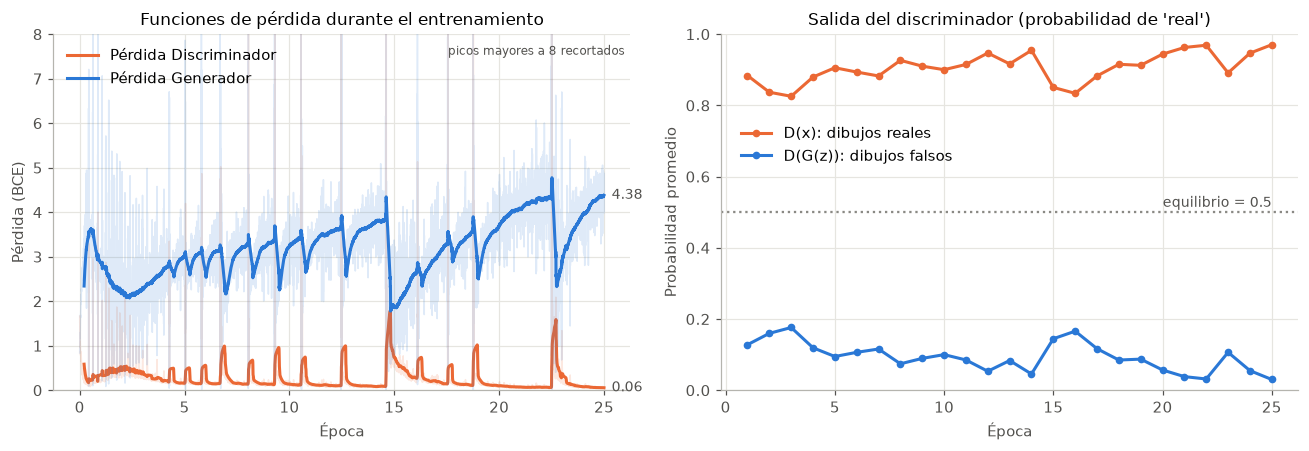

   -> imagen guardada: resultados/04_valores_entrenamiento.png

--- Valores FINALES de los pesos del GENERADOR (después de entrenar) ---
Parámetro                   Forma                   Media    Desv.      Mín      Máx
capa1_lineal.weight         [6272, 100]           -0.0001   0.0266  -0.1236   0.1205
capa1_batchnorm.weight      [6272]                 0.9838   0.1019   0.6516   1.3849
capa1_batchnorm.bias        [6272]                -0.0250   0.1099  -0.3410   0.3300
capa2_deconv.weight         [128, 64, 4, 4]       -0.0031   0.0266  -0.1773   0.2050
capa2_batchnorm.weight      [64]                   1.4171   0.1162   1.1662   1.7006
capa2_batchnorm.bias        [64]                   0.0999   0.1200  -0.2195   0.3496
capa3_deconv.weight         [64, 1, 4, 4]         -0.0363   0.1044  -0.3811   0.2525
capa3_deconv.bias           [1]                    0.1362   0.0000   0.1362   0.1362

--- Valores FINALES de los pesos del DISCRIMINADOR (después de entrenar) ---
Parámetro           

In [10]:
# =============================================================================
# 9. GRÁFICAS DE LOS VALORES DE G Y D
# =============================================================================
def media_movil(valores, ventana=50):
    valores = np.asarray(valores)
    return np.convolve(valores, np.ones(ventana) / ventana, mode="valid")


lotes_por_epoca = len(cargador)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

# --- Pérdidas por lote (suavizadas) ---
for clave, color, nombre in [("perdida_D", COLOR_D, "Discriminador"), ("perdida_G", COLOR_G, "Generador")]:
    bruto = np.array(historial_lotes[clave])
    suave = media_movil(bruto)
    x_bruto = np.arange(len(bruto)) / lotes_por_epoca
    x_suave = (np.arange(len(suave)) + 49) / lotes_por_epoca
    ax1.plot(x_bruto, bruto, color=color, alpha=0.15, linewidth=1)
    ax1.plot(x_suave, suave, color=color, label=f"Pérdida {nombre}")
    ax1.annotate(f"{suave[-1]:.2f}", (x_suave[-1], suave[-1]), xytext=(5, 0),
                 textcoords="offset points", va="center", fontsize=9, color=COLOR_TEXTO)
ax1.set_title("Funciones de pérdida durante el entrenamiento", fontsize=11)
ax1.set_xlabel("Época")
ax1.set_ylabel("Pérdida (BCE)")
# Algunos lotes sueltos tienen picos de hasta ~25; se recorta el eje para que se lean las curvas
ax1.set_ylim(0, 8)
ax1.text(0.99, 0.97, "picos mayores a 8 recortados", transform=ax1.transAxes,
         ha="right", va="top", fontsize=8, color=COLOR_TEXTO)
ax1.legend(frameon=False, loc="upper left")

# --- D(x) y D(G(z)) por época ---
epocas = [f["epoca"] for f in historial_epocas]
d_x = [f["D_x"] for f in historial_epocas]
d_g_z = [f["D_G_z"] for f in historial_epocas]
ax2.plot(epocas, d_x, color=COLOR_D, marker="o", markersize=4, label="D(x): dibujos reales")
ax2.plot(epocas, d_g_z, color=COLOR_G, marker="o", markersize=4, label="D(G(z)): dibujos falsos")
ax2.axhline(0.5, color="#8a8984", linestyle=":", linewidth=1.5)
ax2.text(epocas[-1], 0.515, "equilibrio = 0.5", ha="right", fontsize=9, color=COLOR_TEXTO)
ax2.set_ylim(0, 1)
ax2.set_title("Salida del discriminador (probabilidad de 'real')", fontsize=11)
ax2.set_xlabel("Época")
ax2.set_ylabel("Probabilidad promedio")
# Leyenda en la franja vacía entre las dos curvas, para que no tape ninguna línea
ax2.legend(frameon=False, loc="upper left", bbox_to_anchor=(0.01, 0.78))
fig.tight_layout()
guardar_y_mostrar(fig, "04_valores_entrenamiento.png")

# Valores FINALES de los pesos (comparar con los iniciales de la sección 5)
valores_pesos(G, "Valores FINALES de los pesos del GENERADOR (después de entrenar)")
valores_pesos(D, "Valores FINALES de los pesos del DISCRIMINADOR (después de entrenar)")

## 10. Resultado de la GAN

**Categoría usada: `cat` (gato) de Google Quick Draw.**

Primero se ve cómo el generador pasa de ruido a dibujos de gatos a lo largo de las
épocas (siempre con el mismo ruido de entrada), y luego el resultado final junto a
dibujos reales para comparar.

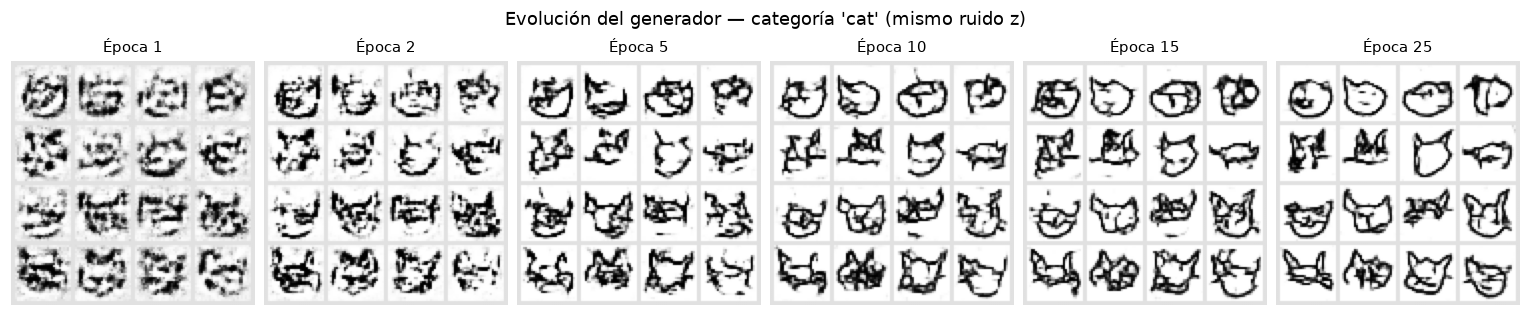

   -> imagen guardada: resultados/05_evolucion_generador.png


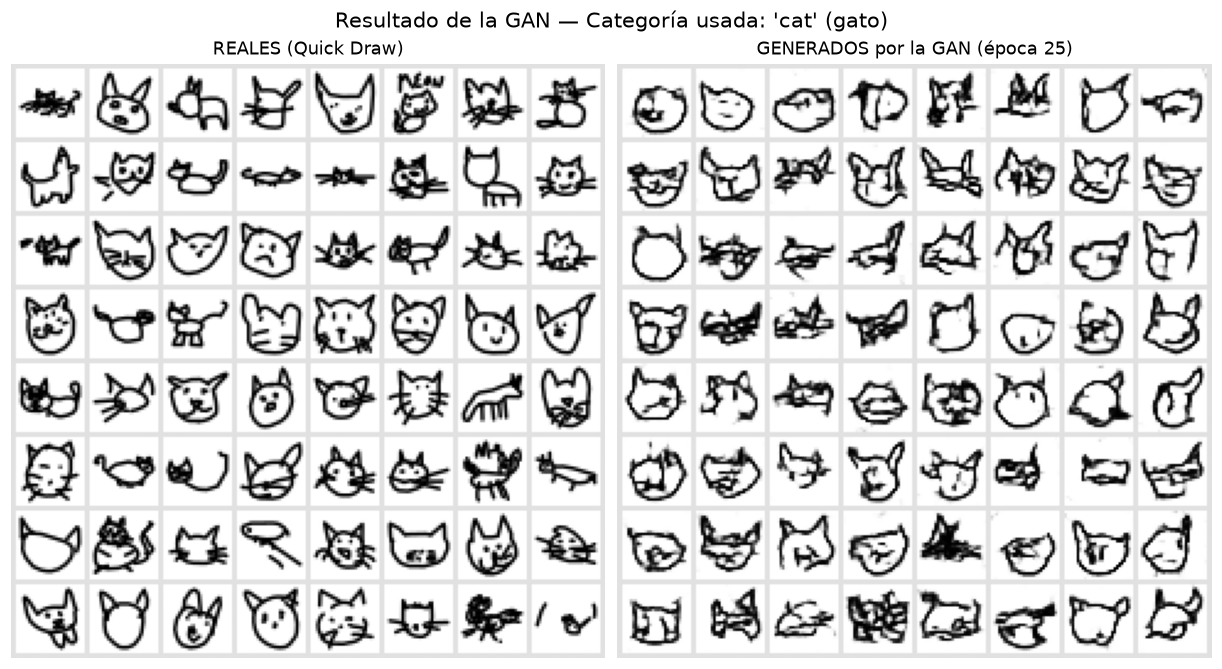

   -> imagen guardada: resultados/06_resultado_gan.png


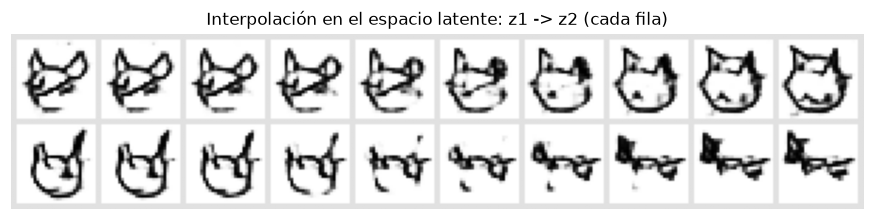

   -> imagen guardada: resultados/07_interpolacion_latente.png


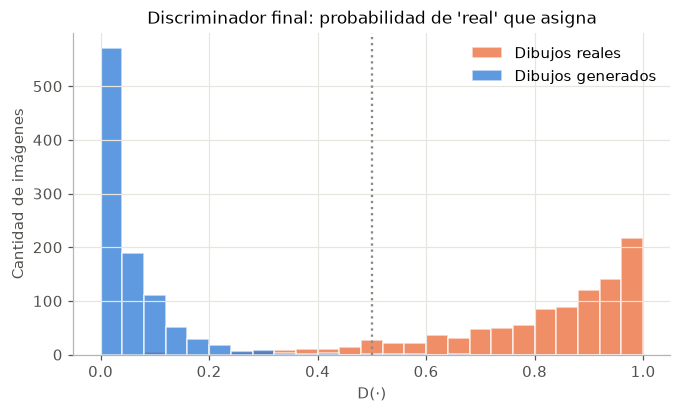

   -> imagen guardada: resultados/08_salida_discriminador.png
   -> animación guardada: resultados/evolucion.gif

RESUMEN FINAL
Categoría usada                    : 'cat' (Google Quick Draw)
Parámetros de la red Generadora    : 771,969
Parámetros de la red Discriminadora: 138,689
Pérdida D / Pérdida G (última época): 0.0640 / 4.2450
D(x) / D(G(z)) (última época)       : 0.970 / 0.030
D promedio en reales / generados    : 0.814 / 0.058
   -> reporte guardado: resultados/reporte_valores.txt y resultados/resumen.json


In [11]:
# =============================================================================
# 10. RESULTADO DE LA GAN
# =============================================================================
# --- Evolución del generador a lo largo de las épocas ---
marcas = sorted({1, 2, 5, 10, 15, EPOCAS} & set(evolucion))
fig, ejes = plt.subplots(1, len(marcas), figsize=(2.3 * len(marcas), 2.9), layout="constrained")
for ax, e in zip(ejes, marcas):
    ax.imshow(hacer_cuadricula(evolucion[e][:16], 4, 4), cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(f"Época {e}", fontsize=10)
    ax.axis("off")
fig.suptitle(f"Evolución del generador — categoría '{CATEGORIA}' (mismo ruido z)", fontsize=12)
guardar_y_mostrar(fig, "05_evolucion_generador.png")

# --- Resultado final: reales vs generados ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 6), layout="constrained")
ax1.imshow(hacer_cuadricula(imagenes_reales[64:128], 8, 8), cmap="gray_r", vmin=0, vmax=1)
ax1.set_title("REALES (Quick Draw)", fontsize=12)
ax1.axis("off")
ax2.imshow(hacer_cuadricula(evolucion[EPOCAS], 8, 8), cmap="gray_r", vmin=0, vmax=1)
ax2.set_title(f"GENERADOS por la GAN (época {EPOCAS})", fontsize=12)
ax2.axis("off")
fig.suptitle(f"Resultado de la GAN — Categoría usada: '{CATEGORIA}' (gato)", fontsize=14)
guardar_y_mostrar(fig, "06_resultado_gan.png")

# --- Interpolación en el espacio latente: de un z a otro ---
# Si la GAN aprendió bien, al moverse poco a poco entre dos vectores z el dibujo
# cambia de forma suave (no salta al azar).
G.eval()
with torch.no_grad():
    extremos = torch.randn(4, DIM_LATENTE, device=DISPOSITIVO)
    pasos = torch.linspace(0, 1, 10, device=DISPOSITIVO).view(-1, 1)
    filas_interp = [(1 - pasos) * extremos[2 * i] + pasos * extremos[2 * i + 1] for i in range(2)]
    interpolacion = G(torch.cat(filas_interp)).cpu().numpy()
G.train()
fig, ax = plt.subplots(figsize=(10, 2.4))
ax.imshow(hacer_cuadricula(interpolacion, 2, 10), cmap="gray_r", vmin=0, vmax=1)
ax.set_title("Interpolación en el espacio latente: z1 -> z2 (cada fila)", fontsize=11)
ax.axis("off")
guardar_y_mostrar(fig, "07_interpolacion_latente.png")

# --- Qué opina el discriminador final de reales vs. falsos ---
G.eval()
D.eval()
with torch.no_grad():
    lote_reales = torch.from_numpy(imagenes_reales[:1000]).to(DISPOSITIVO)
    prob_reales = D(lote_reales).view(-1).cpu().numpy()
    prob_falsos = D(G(torch.randn(1000, DIM_LATENTE, device=DISPOSITIVO))).view(-1).cpu().numpy()
G.train()
D.train()
fig, ax = plt.subplots(figsize=(7, 3.8))
contenedores = np.linspace(0, 1, 26)
ax.hist(prob_reales, bins=contenedores, color=COLOR_D, alpha=0.75, label="Dibujos reales", edgecolor="white")
ax.hist(prob_falsos, bins=contenedores, color=COLOR_G, alpha=0.75, label="Dibujos generados", edgecolor="white")
ax.axvline(0.5, color="#8a8984", linestyle=":", linewidth=1.5)
ax.set_title("Discriminador final: probabilidad de 'real' que asigna", fontsize=11)
ax.set_xlabel("D(·)")
ax.set_ylabel("Cantidad de imágenes")
ax.legend(frameon=False)
guardar_y_mostrar(fig, "08_salida_discriminador.png")

# --- GIF animado de la evolución ---
cuadros = []
for e in sorted(evolucion):
    cuadricula = 1 - hacer_cuadricula(evolucion[e], 8, 8)  # trazo negro, fondo blanco
    cuadro = Image.fromarray((cuadricula * 255).astype(np.uint8)).resize((cuadricula.shape[1] * 3,) * 2, Image.NEAREST)
    cuadros.append(cuadro)
cuadros[0].save(DIR_RESULTADOS / "evolucion.gif", save_all=True, append_images=cuadros[1:],
                duration=350, loop=0)
print("   -> animación guardada: resultados/evolucion.gif")

# --- Resumen final ---
final = historial_epocas[-1]
imprimir()
imprimir("=" * 70)
imprimir("RESUMEN FINAL")
imprimir("=" * 70)
imprimir(f"Categoría usada                    : '{CATEGORIA}' (Google Quick Draw)")
imprimir(f"Parámetros de la red Generadora    : {params_G:,}")
imprimir(f"Parámetros de la red Discriminadora: {params_D:,}")
imprimir(f"Pérdida D / Pérdida G (última época): {final['perdida_D']:.4f} / {final['perdida_G']:.4f}")
imprimir(f"D(x) / D(G(z)) (última época)       : {final['D_x']:.3f} / {final['D_G_z']:.3f}")
imprimir(f"D promedio en reales / generados    : {prob_reales.mean():.3f} / {prob_falsos.mean():.3f}")

(DIR_RESULTADOS / "reporte_valores.txt").write_text("\n".join(REPORTE), encoding="utf-8")
(DIR_RESULTADOS / "resumen.json").write_text(json.dumps({
    "categoria": CATEGORIA,
    "imagenes_entrenamiento": NUM_IMAGENES,
    "epocas": EPOCAS,
    "parametros_generador": params_G,
    "parametros_discriminador": params_D,
    "ultima_epoca": final,
    "D_promedio_reales": float(prob_reales.mean()),
    "D_promedio_generados": float(prob_falsos.mean()),
}, indent=2, ensure_ascii=False), encoding="utf-8")
print("   -> reporte guardado: resultados/reporte_valores.txt y resultados/resumen.json")